# 25 · Structures: internal layout, a layout-based weight back-check, and the CalculiX wing check

In this code base **structures inside the sizing are mass estimation only**: handbook and AFDD correlations, calibrated (tutorials 12, 23). Stress,
deflection and frequencies by finite elements are a **downstream check** on the sized design, never imported by the sizing (a user decision recorded in
`docs/CODING_CONVENTIONS.md`). This notebook walks through that check chain, all of it in `export/openvsp/`:

1. `structure.py`: the internal structure in OpenVSP (spars, ribs, skins, frames, bulkheads, floor), meshed and exported as STL, CalculiX and Nastran decks.
2. `structure_check.py`: a **layout-based** primary-structure sizing (real box depth, spanwise loads, simple criteria) to back-check the sizing's wing weight.
3. `fe_wing.py`: a **CalculiX** shell model of the wing box carrying exactly the structure the AFDD wing model weighed; free-free frequencies against AFDD's
   estimates, and strain in the ultimate jump take-off against the allowable.

The headline you should be able to explain afterwards: **the FE check puts the peak spar-cap strain above the ultimate allowable (a negative margin)**, why, and
what would fix it.

**Requires** OpenVSP (tutorial 24) and CalculiX (`ccx`; set the `CCX` environment variable or install it at the path in `examples/halo_wing_fe.py`). Outputs go
to `output/tutorials/structures/`.

**Run time:** about 2 minutes the first time (the CalculiX frequency analysis takes about 90 s), then cached.

In [1]:
from tutorial_helpers import *
import numpy as onp
import inspect, os, time
from pathlib import Path
from dataclasses import replace, fields
from IPython.display import Image, display
from examples.halo_sizing import HaloRequirements, HaloAssumptions, solve_halo_sizing, build_halo_aircraft
from aircraft_closure.vehicle.condition import StructuralDesignCondition
requirements = HaloRequirements()
reference = cached("reference_scholz", lambda: solve_halo_sizing(requirements, replace(HaloAssumptions(), aerodynamics_model="scholz")))
counts = {name: whole for name, (relaxed, whole) in reference.machine_units.items()}
assumptions = replace(HaloAssumptions(), aerodynamics_model="scholz", count_units_motor=counts["motor"],
                      count_units_generator=counts["generator"])
directory = output_dir / "structures"
directory.mkdir(parents=True, exist_ok=True)
import examples.halo_wing_fe as wing_fe_example
path_ccx = wing_fe_example.path_ccx
print(f"CalculiX: {path_ccx} ({'found' if path_ccx.exists() else 'NOT FOUND: set CCX'})")

CalculiX: C:\Users\alexa\Documents\Xenon\Software\CalculiX\CalculiX-2.22.0-win-x64\bin\ccx.exe (found)


## 1. What the sizing booked

Everything downstream checks the structure the sizing weighed. Collect it from the solved design, as `examples/halo_structure_reference.py` does: the structural
design condition, the AFDD wing breakdown (masses, required stiffnesses, the jump take-off moment), the material, tip mass and pylon inertia:

In [2]:
def structure_reference(result, assumptions):
    aircraft = build_halo_aircraft(result.design, requirements, assumptions)
    condition = StructuralDesignCondition(mass_design_kg=result.mass_takeoff_kg, load_factor_ultimate=assumptions.load_factor_ultimate,
                                          velocity_cruise_m_s=result.velocity_cruise_m_s, altitude_cruise_m=requirements.altitude_cruise_m,
                                          lift_to_drag_cruise=result.lift_to_drag_cruise)
    wing, model = aircraft.wing, aircraft.wing.mass_model
    masses = model.masses(wing, condition)
    return dict(mass_takeoff_kg=float(result.mass_takeoff_kg), load_factor_ultimate=float(assumptions.load_factor_ultimate),
                load_factor_jump=float(assumptions.load_factor_jump), span_wing_m=float(wing.span_m()), area_wing_m2=float(wing.area_m2),
                thickness_to_chord_wing=float(model.thickness_to_chord), width_fuselage_m=float(model.width_fuselage_m),
                mass_tip_kg=float(model.mass_tip_kg), radius_gyration_pylon_m=float(model.radius_gyration_pylon_m),
                x_le_wing_m=float(result.design.x_le_wing_m), z_wing_m=float(wing.z_m), radius_rotor_m=float(result.radius_rotor_m),
                material_wing={f.name: float(getattr(model.material, f.name)) for f in fields(model.material)},
                wing_afdd={f.name: float(getattr(masses, f.name)) for f in fields(masses)},
                mass_wing_kg=float(aircraft.get_mass_breakdown(condition).wing.mass), factor_wing=float(wing.mass_factor))

r = structure_reference(reference, assumptions)
afdd = r["wing_afdd"]
print(f"design mass {r['mass_takeoff_kg']:,.0f} kg; ultimate load factor {r['load_factor_ultimate']}; jump load factor {r['load_factor_jump']}; "
      f"tip mass {r['mass_tip_kg']:.0f} kg each")
print(f"wing {r['span_wing_m']:.2f} m span, {r['area_wing_m2']:.1f} m2, t/c {r['thickness_to_chord_wing']}, material strain allowable "
      f"{r['material_wing']['strain_ultimate']} (graphite-epoxy)")
print(f"AFDD: torque box {afdd['mass_torque_box_kg']:.1f} kg, caps for stiffness {afdd['mass_spar_stiffness_kg']:.1f} kg, caps for the jump "
      f"{afdd['mass_spar_jump_kg']:.1f} kg, fairing {afdd['mass_fairing_kg']:.1f} kg; x {r['factor_wing']:.3f} calibration = {r['mass_wing_kg']:.0f} kg booked")
print(f"AFDD frequencies [rad/s]: beam {afdd['frequency_beam_rad_s']:.1f}, chord {afdd['frequency_chord_rad_s']:.1f}, torsion "
      f"{afdd['frequency_torsion_rad_s']:.1f}; ultimate jump root moment {afdd['moment_jump_ultimate_Nm'] / 1e3:.0f} kN m")

design mass 6,865 kg; ultimate load factor 4.5; jump load factor 2.0; tip mass 765 kg each
wing 11.93 m span, 23.2 m2, t/c 0.23, material strain allowable 0.0047 (graphite-epoxy)
AFDD: torque box 85.0 kg, caps for stiffness 25.6 kg, caps for the jump 17.9 kg, fairing 73.0 kg; x 1.327 calibration = 407 kg booked
AFDD frequencies [rad/s]: beam 27.8, chord 46.5, torsion 61.5; ultimate jump root moment 393 kN m


Note the **calibration factor** (about 1.33, from the XV-15): the sizing books the AFDD structure × 1.33. Whether that extra third is load-carrying material
or non-structural mass the AFDD method misses is an open question, and it matters below.

## 2. The internal structure in OpenVSP

`build_structure(snapshot, layout)` adds OpenVSP FEA structures to the outer mold line of tutorial 24 (`StructureLayout` holds every placement and placeholder gauge):

- **wing**: front and rear spars at 15 % and 60 % chord (the AFDD box), a rib array every 0.5 m, attach ribs at the fairing sides, a nacelle rib at the spindle,
  upper and lower skins;
- **fuselage**: 0.6 m ring frames (I-section beams), bulkheads at the nose bay, both wing-spar stations and the cabin end, a cabin floor, skin;
- **V-tail**: two spars and ribs, skin.

The FE check uses the **as-sized** wing (constant chord, the sizing's geometry) rather than the tapered drawing. Mesh the wing box and the V-tail (the fuselage frames
take a few minutes to mesh, so they are left to `examples/halo_structure.py`):

In [3]:
from aircraft_closure.export.openvsp.snapshot import SurfaceSnapshot, halo_plan027_snapshot
from aircraft_closure.export.openvsp.structure import StructureLayout, build_structure, export_structure_meshes
from aircraft_closure.export.openvsp.model import export_outer_mold_line
layout = StructureLayout()
chord_m = r["area_wing_m2"] / r["span_wing_m"]
wing_as_sized = SurfaceSnapshot(span_m=r["span_wing_m"], chord_root_m=chord_m, chord_tip_m=chord_m, x_le_root_m=r["x_le_wing_m"], z_m=r["z_wing_m"],
                                thickness_to_chord=r["thickness_to_chord_wing"], camber=0.02)
snapshot = replace(halo_plan027_snapshot(), wing=wing_as_sized)
print(layout)
time_start_s = time.perf_counter()
with quiet_output():
    paths_oml = export_outer_mold_line(snapshot, directory / "outer_mold_line", angles_nacelle_deg=(0.0,))
    geoms, structures = build_structure(snapshot, layout)
    paths = export_structure_meshes({name: structures[name] for name in ("WingBox", "VTail")}, directory, kinds=("stl", "calculix"))
print(f"structures {list(structures)}; meshed WingBox and VTail in {time.perf_counter() - time_start_s:.0f} s")
for key, path in paths.items():
    print(f"   {str(key):<24} {path.name}")

StructureLayout(fraction_chord_front_spar=0.15, fraction_chord_rear_spar=0.6, pitch_rib_wing_m=0.5, pitch_frame_m=0.6, height_floor_above_bottom_m=0.35, x_bulkhead_nose_m=1.6, x_cabin_end_m=5.06, pitch_rib_tail_m=0.4, thickness_skin_m=0.002, thickness_spar_web_m=0.004, thickness_rib_m=0.002, thickness_bulkhead_m=0.0015, thickness_floor_m=0.003, depth_frame_m=0.075, width_flange_frame_m=0.03, thickness_frame_m=0.0016)


structures ['WingBox', 'Fuselage', 'VTail']; meshed WingBox and VTail in 14 s
   ('WingBox', 'stl')       WingBox.stl
   ('WingBox', 'calculix')  WingBox.inp
   ('VTail', 'stl')         VTail.stl
   ('VTail', 'calculix')    VTail.inp


C:\Users\alexa\Documents\Chasing Amber\halo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


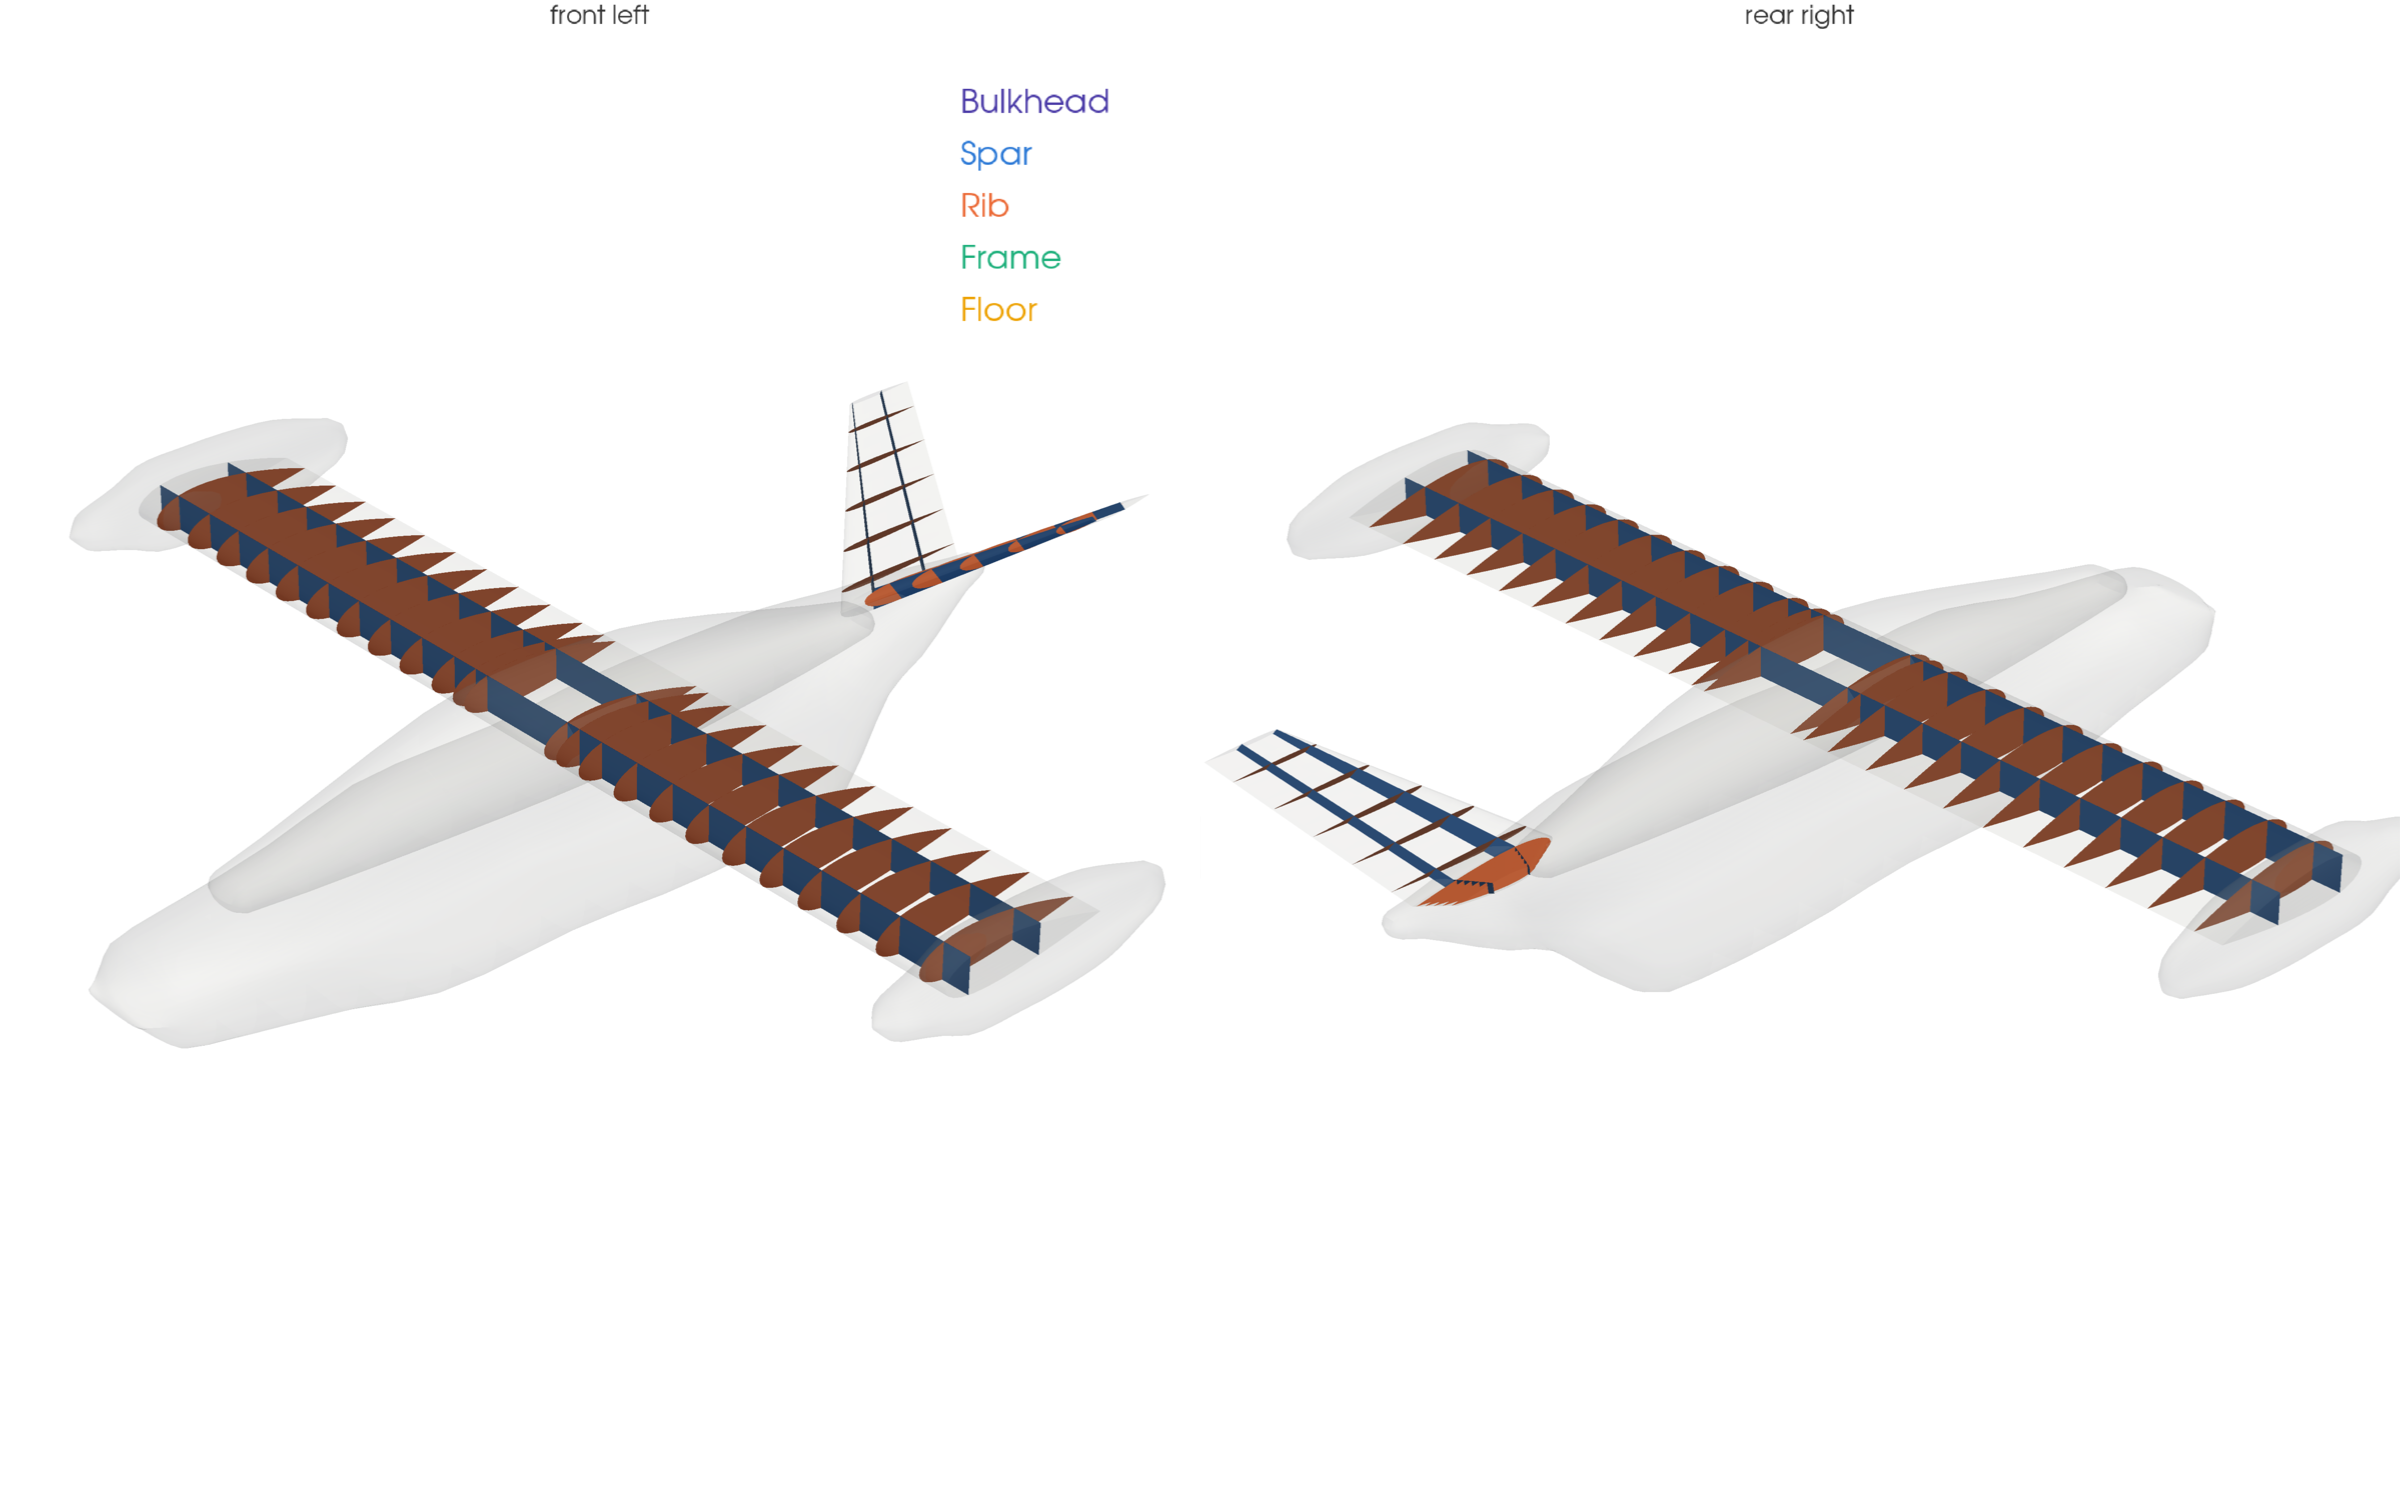

In [4]:
from aircraft_closure.export.openvsp.render import render_structure
with quiet_output():
    render_structure([paths[("WingBox", "stl")], paths[("VTail", "stl")]], paths_oml[("stl_airframe", 0.0)], directory / "structure.png")
apply_style()
display(Image(filename=str(directory / "structure.png"), width=1000))

## 3. A layout-based back-check of the wing weight

The AFDD method sizes an idealized uniform box from frequency and jump-moment relations. `structure_check.size_box` sizes the **drawn** box instead: the real box
between the spars with the airfoil's depth there, spanwise bending moment and shear (flight at the ultimate load factor with elliptic lift and tip-mass relief, or
the jump take-off, whichever governs at each station), skins and webs from strength and minimum gauge, spar caps from strength and the AFDD stiffness requirements,
ribs by area. `examples/halo_structure_check.py: wing_check` sets it up; run it on the as-sized wing:

root moment 402 kN m (jump governs); skins 1.22 mm at the root
layout primary structure: skins 42.3 + webs 17.9 + caps 54.8 + ribs 20.4 = 135.4 kg
AFDD primary structure (box + caps): 128.6 kg; x 1.327 = 170.6 kg


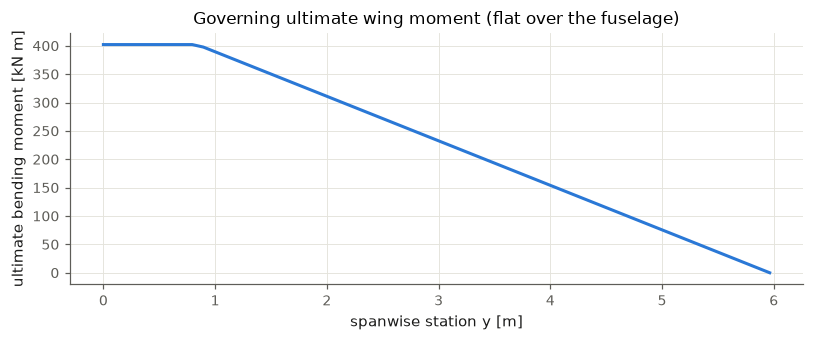

In [5]:
from aircraft_closure.export.openvsp.structure_check import area_by_part_m2
from examples.halo_structure_check import wing_check
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")      # the example module switches matplotlib to a file-only backend
area_ribs_m2 = sum(area_by_part_m2(paths[("WingBox", "stl")], name) for name in ("Ribs", "FairingAttachRib", "NacelleRib"))
box, loads, material = wing_check(r, layout, 1.0, area_ribs_m2, "uniform")
mass_afdd_primary_kg = afdd["mass_torque_box_kg"] + afdd["mass_spar_stiffness_kg"] + afdd["mass_spar_jump_kg"]
print(f"root moment {loads.moment_Nm[0] / 1e3:.0f} kN m ({loads.case[0]} governs); skins {1e3 * box.thickness_skin_m[0]:.2f} mm at the root")
print(f"layout primary structure: skins {box.mass_skins_kg:.1f} + webs {box.mass_webs_kg:.1f} + caps {box.mass_caps_kg:.1f} + ribs {box.mass_ribs_kg:.1f} "
      f"= {box.mass_primary_kg():.1f} kg")
print(f"AFDD primary structure (box + caps): {mass_afdd_primary_kg:.1f} kg; x {r['factor_wing']:.3f} = {mass_afdd_primary_kg * r['factor_wing']:.1f} kg")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(loads.y_m, loads.moment_Nm / 1e3, color=blue, lw=2)
ax.set(xlabel="spanwise station y [m]", ylabel="ultimate bending moment [kN m]", title="Governing ultimate wing moment (flat over the fuselage)")
plt.tight_layout(); plt.show()

The two methods weigh the same box by different routes; agreement within tens of percent says the AFDD estimate is in the right range for this layout. The
comparison is in `docs/decisions/031` and `038` (the 1 mm minimum gauge and the real spar-cap depth came from it).

## 4. The CalculiX wing check

`fe_wing.py` turns the OpenVSP wing-box mesh (S8 shells: skins, spars, ribs, both halves) into a model of **the structure the AFDD model weighed**:

| Part | Property |
|---|---|
| box walls (skins between the spars, spar webs) | the AFDD torque-box wall area spread over the box perimeter as one thickness |
| spar caps | the AFDD cap area as thickened skin strips over each spar (four caps) |
| leading and trailing edges | non-structural fairing (very low modulus) carrying the AFDD fairing mass |
| ribs | a stated gauge of the box material |
| each tip | the nacelle rib plus two point masses (the tip mass, split fore and aft by the pylon radius of gyration) forming a rigid body |

Two analyses:

- **frequencies**, free-free: the nodes over the fuselage form a rigid body carrying the rest of the aircraft's mass and inertia; beam, chord and torsion modes are
  identified from the nacelles' rigid-body motion and compared with AFDD's single-mode estimates;
- **jump take-off at ultimate load** (AFDD's case: rotor thrust at the tips less tip inertia, × 1.5), wing clamped over the fuselage width: tip deflection and the
  largest spanwise spar-cap strain in a band outboard of the clamp (the clamp edge itself is a stress singularity).

In [6]:
from aircraft_closure.export.openvsp.fe_wing import (FuselageMass, TipMass, properties_from_afdd, read_mesh, read_modes, read_static,
                                                      run_calculix, write_deck)
nodes, elsets = read_mesh(paths[("WingBox", "calculix")])
properties = properties_from_afdd(afdd, r["material_wing"], chord_m, r["thickness_to_chord_wing"], layout.fraction_chord_front_spar,
                                  layout.fraction_chord_rear_spar, r["span_wing_m"], r["width_fuselage_m"], width_cap_strip_fraction=0.10)
print(f"{len(nodes):,} nodes; box walls {1e3 * properties.thickness_box_m:.2f} mm, cap pads +{1e3 * properties.thickness_cap_pad_m:.2f} mm over "
      f"{1e3 * properties.width_cap_strip_m:.0f} mm strips, ribs {1e3 * properties.thickness_rib_m:.1f} mm")
tip = TipMass(mass_kg=r["mass_tip_kg"], radius_gyration_pitch_m=r["radius_gyration_pylon_m"], xyz_spindle_m=snapshot.spindle_xyz_m())
weight_N = r["mass_takeoff_kg"] * 9.80665
force_jump_N = 1.5 * (r["load_factor_jump"] * weight_N / 2 - r["load_factor_jump"] * r["mass_tip_kg"] * 9.80665)
mass_wing_structure_kg = afdd["mass_torque_box_kg"] + afdd["mass_spar_stiffness_kg"] + afdd["mass_spar_jump_kg"] + afdd["mass_fairing_kg"]
x_spindle_m, _, z_spindle_m = tip.xyz_spindle_m
fuselage = FuselageMass(mass_kg=r["mass_takeoff_kg"] - 2 * r["mass_tip_kg"] - mass_wing_structure_kg, xyz_cg_m=(x_spindle_m, 0.0, z_spindle_m - 1.0),
                        radius_gyration_pitch_m=3.3, radius_gyration_roll_m=0.6)          # rest of the aircraft (assumed), as the example
deck = dict(nodes=nodes, elsets=elsets, properties=properties, tip=tip, x_le_m=wing_as_sized.x_le_root_m, chord_m=chord_m,
            fraction_front_spar=layout.fraction_chord_front_spar, fraction_rear_spar=layout.fraction_chord_rear_spar, width_fuselage_m=r["width_fuselage_m"])
path_modal, path_jump = directory / "wing_modes.inp", directory / "wing_jump.inp"
references, groups = write_deck(path_modal, fuselage=fuselage, **deck)
write_deck(path_jump, force_tip_jump_N=force_jump_N, **deck)
print(f"decks written: {path_modal.name}, {path_jump.name}; jump load {force_jump_N / 1e3:.1f} kN up at each spindle (ultimate)")
print(f"element groups: " + ", ".join(f"{k} {len(v)}" for k, v in groups.items()))

34,016 nodes; box walls 1.00 mm, cap pads +4.32 mm over 195 mm strips, ribs 1.5 mm


decks written: wing_modes.inp, wing_jump.inp; jump load 78.5 kN up at each spindle (ultimate)
element groups: BOX 1638, CAP 1679, FAIRING 4357, WEB 2184, RIB 2160


In [7]:
def run_fe():
    with quiet_output():
        modes = read_modes(run_calculix(path_modal, path_ccx), references, tip.radius_gyration_pitch_m)
        deflection_m, strain_max = read_static(run_calculix(path_jump, path_ccx), references)
    return modes, deflection_m, strain_max

modes, deflection_m, strain_max = cached("fe_wing_scholz_reference", run_fe)
print("global modes [rad/s]: " + ", ".join(f"{m.frequency_rad_s:.1f} {m.kind}{'' if m.symmetric else ' (anti)'}" for m in modes if m.kind != "local"))
rows = []
for kind, key in (("beam", "frequency_beam_rad_s"), ("chord", "frequency_chord_rad_s"), ("torsion", "frequency_torsion_rad_s")):
    symmetric = [m.frequency_rad_s for m in modes if m.kind == kind and m.symmetric]
    fe = symmetric[0] if symmetric else float("nan")
    rows.append((kind, fe, afdd[key]))
    print(f"   symmetric {kind:<8} FE {fe:6.1f} rad/s   AFDD {afdd[key]:6.1f} rad/s   ratio {fe / afdd[key]:.2f}")
allowable = r["material_wing"]["strain_ultimate"]
margin = (allowable - strain_max) / allowable
print(f"\njump take-off at ultimate: tip deflection {deflection_m:.3f} m; peak spanwise cap strain {strain_max:.5f} against the allowable {allowable:.4f}")
print(f"strain margin {margin:+.1%}  ->  {'NEGATIVE: the booked structure does not carry ultimate load in this model' if margin < 0 else 'positive'}")
check("the FE check finds a negative strain margin in the ultimate jump take-off (as on the full reference)", margin < 0)
check("FE torsion frequency is below AFDD's estimate (the whirl-flutter margin is optimistic)", rows[2][1] < rows[2][2])

global modes [rad/s]: 23.2 beam, 41.9 torsion (anti), 44.0 torsion (anti), 44.0 torsion, 48.3 chord, 48.9 chord, 50.5 torsion (anti), 50.7 chord
   symmetric beam     FE   23.2 rad/s   AFDD   27.8 rad/s   ratio 0.83
   symmetric chord    FE   48.3 rad/s   AFDD   46.5 rad/s   ratio 1.04
   symmetric torsion  FE   44.0 rad/s   AFDD   61.5 rad/s   ratio 0.72

jump take-off at ultimate: tip deflection 0.242 m; peak spanwise cap strain 0.00507 against the allowable 0.0047
strain margin -7.8%  ->  NEGATIVE: the booked structure does not carry ultimate load in this model
PASS  the FE check finds a negative strain margin in the ultimate jump take-off (as on the full reference)
PASS  FE torsion frequency is below AFDD's estimate (the whirl-flutter margin is optimistic)


**Reading the frequencies.** AFDD's single-mode relations treat each mode separately on a uniform beam with a lumped tip; the FE model has the real mesh, rib flexibility,
the coupled pylon inertia and a free-free fuselage body, so some spread is expected. Beam and chord land within about 20 %. **Torsion is the outlier: the FE gives about
0.7 of AFDD's estimate.** That matters because the sizing's whirl-flutter margin (tutorial 23) uses AFDD's torsion frequency, so that margin is optimistic by about the
same factor. The margins were slack on this design (torsion about 2.2 per rev against 1.09 required), so the placement still holds, but it is the number a whirl-flutter
analysis should confirm first.

**Reading the strain: a negative margin.** The booked structure, with the AFDD gauges, is strained beyond the ultimate allowable in the jump take-off. That is not
acceptable for a real aircraft, and the user's standing instruction is to state it as a negative margin, never as "1.08×". What the diagnosis on the full reference
found (scratch runs on the full reference, 2026-10-07; not yet written into the decision log, the result itself is in `docs/RESULTS.md` and the README):

- **It is not torsion**: moving the load from the spindle to mid-box leaves the strains unchanged; closed-form warping adds only 0.01-0.04.
- **The FE maps the raw AFDD gauges, without the 1.33 calibration** the sizing books. If that extra mass were load-carrying material, the peak would fall to about
  0.83 of the allowable (a positive margin). Whether it is, is the open decision.
- **Shear lag at the root clamp** with 1 mm covers concentrates strain in the front cap (about 1.7× the rear, where beam theory gives 1.2×).
- **No buckling analysis yet**: the decks are linear static and frequency only. Plate estimates say the 1 mm unstiffened covers and webs buckle far below ultimate,
  so the real structure needs stiffening, which also adds mass.

## Limits and next steps

**What it can't do**

- **Strength at ultimate load is not demonstrated** (the negative margin above), and there is **no buckling step**.
- **Idealized supports**: a full clamp over the fuselage width for the jump (no fittings, no fuselage flexibility); an assumed rigid fuselage body for the modes.
- **Placeholder layout and gauges** outside the wing box (fuselage frames, floor, V-tail); the fuselage FE is not run here.
- **Whirl flutter is still a frequency margin**: no rotor aerodynamics, no damping, no eigenvalue stability analysis.
- **Nothing feeds back**: the sizing does not see these results, by design.

**What's next** (README stress and aeroelasticity work package)

1. Decide how much of the 1.33 calibration is load-carrying and map it; add realistic fittings and supports.
2. A buckling step (`*BUCKLE` in CalculiX, SOL 105 in Nastran) and stiffened panels sized to a margin ≥ 0 at ultimate.
3. Return calibrated wing weights to the sizing, and add a spar-cap strain margin ≥ 0 as a sizing constraint.
4. Nastran flutter (SOL 145) and whirl flutter with rotor aerodynamics, replacing the frequency margins.

## Summary

- Structures in the sizing are mass estimates; the FE chain (OpenVSP structure → layout back-check → CalculiX) checks the sized design and never feeds back.
- The CalculiX model carries exactly the AFDD-booked structure (walls, caps, fairing, tip masses), so it tests the sizing's own assumptions.
- Frequencies agree with AFDD's estimates to within the expected spread; the jump take-off strain gives a **negative margin**, explained by the uncalibrated gauges,
  root shear lag and the missing buckling and fitting detail.

## Check yourself

<details><summary>1. Why does the FE model use the AFDD gauges rather than sizing its own?</summary>

Its job is to check the structure the sizing booked. Mapping the AFDD walls and caps onto the mesh tests whether that booked structure carries the loads and has the frequencies the sizing assumed. Sizing new gauges would answer a different question (what the structure should be), which is the next step.
</details>

<details><summary>2. Someone reads "1.08 × the allowable" as "8 % over, close enough". What do you say?</summary>

At ultimate load there is no "close enough": the margin is negative, so the structure as booked fails the requirement. It may be resolved by mapping the calibration mass as structure (about 0.83 of the allowable), but that is a decision with evidence, not an assumption, and buckling has not been checked at all yet.
</details>

In [8]:
check_summary()

2 of 2 checks passed
